<a href="https://colab.research.google.com/github/Faheemmundoli/house-price-prediction-ml/blob/main/Lab%205%3A%20Logistic%20Regression" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Faheem M 2427010572

# Lab 5: Logistic Regression

### Objectives:
1. Prepare a dataset for binary classification.
2. Implement Logistic Regression to predict a yes/no outcome.
3. Evaluate the model using accuracy, precision, recall and F1-score.
4. Visualize performance using a confusion matrix.
5. Analyze the model using the ROC curve and AUC score.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)

folder = kagglehub.dataset_download("heesoo37/120-years-of-olympic-history-athletes-and-results")
df = pd.read_csv(folder + "/athlete_events.csv")
df['Medal_Binary'] = df['Medal'].notna().astype(int)

Using Colab cache for faster access to the '120-years-of-olympic-history-athletes-and-results' dataset.


## 1. Data Preparation :
The target is Medal_Binary (1 = won a medal, 0 = no medal). The input features are Age, Height and Weight. Rows with missing values are removed.

In [ ]:
df_clf = df.dropna(subset=['Age', 'Height', 'Weight'])

X = df_clf[['Age', 'Height', 'Weight']]
y = df_clf['Medal_Binary']

print(y.value_counts())

Medal_Binary
0    175984
1     30181
Name: count, dtype: int64


## 2. Train-Test Split and Model Training :
The data is split 80% for training and 20% for testing. Logistic Regression learns the probability of a medal using the sigmoid function. class_weight='balanced' stops the model from simply predicting "no medal" every time.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

## 3. Evaluation Metrics :
Accuracy, precision, recall and F1-score measure how well the model classifies the test data.

In [ ]:
print(f"Accuracy : {accuracy_score(y_test, y_pred):.2f}")
print(f"Precision: {precision_score(y_test, y_pred):.2f}")
print(f"Recall   : {recall_score(y_test, y_pred):.2f}")
print(f"F1-score : {f1_score(y_test, y_pred):.2f}")
print()
print(classification_report(y_test, y_pred, target_names=['No Medal', 'Medal']))

Accuracy : 0.55
Precision: 0.18
Recall   : 0.55
F1-score : 0.27

              precision    recall  f1-score   support

    No Medal       0.88      0.55      0.68     35197
       Medal       0.18      0.55      0.27      6036

    accuracy                           0.55     41233
   macro avg       0.53      0.55      0.47     41233
weighted avg       0.78      0.55      0.62     41233



## 4. Confusion Matrix :
The confusion matrix compares actual and predicted classes. It shows true negatives, false positives, false negatives and true positives.

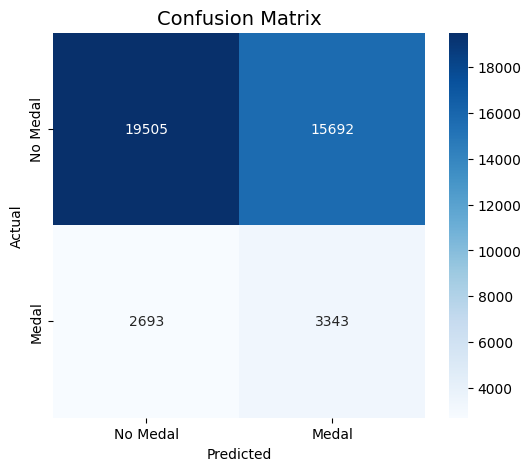

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Medal', 'Medal'], yticklabels=['No Medal', 'Medal'])
plt.title('Confusion Matrix', fontsize=14)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 5. ROC Curve :
The ROC curve plots the true positive rate against the false positive rate at different thresholds. The AUC score summarizes it: 1.0 is perfect and 0.5 is random guessing.

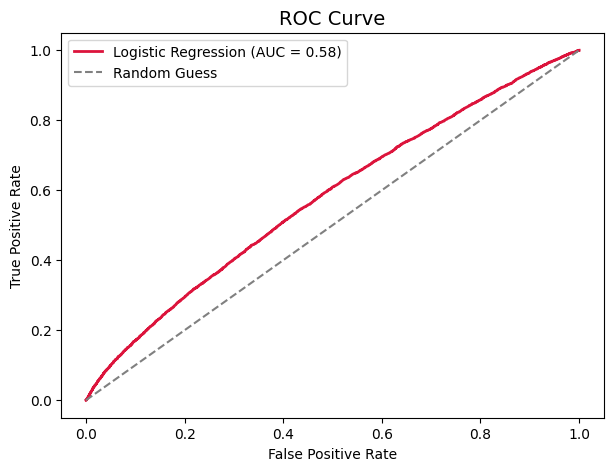

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='crimson', linewidth=2, label=f'Logistic Regression (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess')
plt.title('ROC Curve', fontsize=14)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()